# Decision Tree Classifier

In this notebook, I will use a pipeline to preprocess the data and train a decision tree classifier on the training set using default settings.

Next, I will use cross-validation to calculate metrics and compare the results with those of DummyClassifier.

Metrics:
- Accuracy
- Precision
- Recall
- F1

Diagnostic plots:
- Precision-recall curve

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    confusion_matrix,
    precision_recall_curve,
)
from sklearn.model_selection import (
    cross_val_score,
    cross_validate,
    cross_val_predict,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    LabelEncoder,
)
from sklearn.tree import DecisionTreeClassifier

from telco_churn.config import (
    TARGET_COLUMN,
    ID_COLUMN,
    BINARY_COLUMN,
    CATEGORICAL_COLUMNS,
    NUMERICAL_COLUMNS,
    RANDOM_STATE,
)
from telco_churn.paths import TELCO_CUSTOMERS_TRAIN_PATH

In [2]:
# Define metrics for cross-validation and summary statistics
METRICS = ['accuracy', 'precision', 'recall', 'f1']

In [3]:
# Helpers
def cv_mean_std(cv_results, metrics):
    """
    Calculate the mean and standard deviation of cross-validation scores.
    """
    test_metric_columns = [f'test_{metric}' for metric in metrics]
    df = pd.DataFrame(cv_results)[test_metric_columns]
    
    mean = df.mean()
    mean.name = 'mean'
    
    std = df.std(ddof=0)
    std.name = 'std'

    return pd.concat([mean, std], axis=1).round(4)

## Load the training set and separate features from the target

In [4]:
# Load the training dataset
df_train = pd.read_csv(TELCO_CUSTOMERS_TRAIN_PATH)

In [5]:
# Display first three rows to inspect the loaded data
df_train.head(3)

,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
0,2926-JEJJC,Female,0,No,No,8,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Bank transfer (automatic),20.20,140.95,No
1,6029-CSMJE,Male,0,No,No,17,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,25.65,440.20,No
2,7321-ZNSLA,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,...,No,Yes,No,No,Two year,No,Mailed check,40.55,590.35,No


In [6]:
# Prepare training features by dropping the identifier (customer_id) and target (churn) columns
X_train = df_train.drop(
    columns=[
        TARGET_COLUMN,
        ID_COLUMN,
    ]
)

In [7]:
# Prepare the training target
y_train = df_train[TARGET_COLUMN].copy()

## Preprocess features and encode the target

In [8]:
# Configure feature preprocessing
cat_encoder = OneHotEncoder(
    drop='if_binary',
    handle_unknown='ignore',
)

# Encode categorical features and pass numerical features and senior_citizen through unchanged
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', cat_encoder, list(CATEGORICAL_COLUMNS)),
        ('num', 'passthrough', list(NUMERICAL_COLUMNS)),
        ('senior_citizen', 'passthrough', [BINARY_COLUMN]),
    ]
)

In [9]:
# Encode the training target
target_encoder = LabelEncoder()
y_train_prep = target_encoder.fit_transform(y_train)

In [10]:
# Confirm the target class mapping
target_encoder.classes_

array(['No', 'Yes'], dtype=object)

## Train a Decision Tree Classifier

In [11]:
# Train a decision tree pipeline with default hyperparameters and a fixed random_state
decision_tree_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', DecisionTreeClassifier(random_state=RANDOM_STATE)),
])

decision_tree_pipeline.fit(
    X_train,
    y_train_prep,
)

,steps,"[('prep', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('cat', ...), ('num', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [12]:
# Inspect the maximum depth of the trained decision tree
decision_tree_pipeline.named_steps['model'].get_depth()

21

In [13]:
# Inspect number of leaves
decision_tree_pipeline.named_steps['model'].get_n_leaves()

np.int64(1103)

In [14]:
# Inspect number of nodes
decision_tree_pipeline.named_steps['model'].tree_.node_count

2205

## Calculate metrics using cross-validation

In [15]:
# Decision treee accuracy
decision_tree_train_prediction = decision_tree_pipeline.predict(X_train)
decision_tree_train_accuracy = (decision_tree_train_prediction == y_train_prep).mean().round(4)

decision_tree_train_accuracy.round(4)

np.float64(0.9982)

In [16]:
# Evaluate the decision tree classifier using 5-fold cross-validation
decision_tree_cv_results = cross_validate(
    decision_tree_pipeline,
    X_train,
    y_train_prep,
    cv=5,
    scoring=METRICS,
)

decision_tree_cv_results

{'fit_time': array([0.05681586, 0.05325913, 0.05356169, 0.05507374, 0.0525434 ]),
 'score_time': array([0.01663852, 0.01545477, 0.01500845, 0.01560664, 0.01544857]),
 'test_accuracy': array([0.75066548, 0.74179237, 0.73114463, 0.73558119, 0.71580817]),
 'test_precision': array([0.52777778, 0.51190476, 0.49371069, 0.50163934, 0.46366782]),
 'test_recall': array([0.57190635, 0.57525084, 0.52508361, 0.51170569, 0.44816054]),
 'test_f1': array([0.54895666, 0.54173228, 0.5089141 , 0.50662252, 0.45578231])}

In [17]:
# Summarize cross-validation scores using the cv_mean_std helper
decision_tree_cv_results_stats = cv_mean_std(
    cv_results=decision_tree_cv_results,
    metrics=METRICS,
)

decision_tree_cv_results_stats

,mean,std
test_accuracy,0.7350,0.0116
test_precision,0.4997,0.0213
test_recall,0.5264,0.0465
test_f1,0.5124,0.0330


In [18]:
# Generate out-of-fold predictions for the decision tree classifier
decision_tree_cv_predictions = cross_val_predict(
    decision_tree_pipeline,
    X_train,
    y_train_prep,
    cv=5,
)

In [19]:
# Confusion matrix for Decision tree classifier
decision_tree_cm = confusion_matrix(
    y_train_prep,
    decision_tree_cv_predictions,
)

decision_tree_cm

array([[3354,  785],
       [ 708,  787]])

In [20]:
# Generate out-of-fold probabilities for the decision tree classifier
decision_tree_cv_probabilities = cross_val_predict(
    decision_tree_pipeline,
    X_train,
    y_train_prep,
    cv=5,
    method='predict_proba',
)

# Selecting probabilities for positive (churn) class
decision_tree_churn_proba = decision_tree_cv_probabilities[:, 1]

In [21]:
# Compute the precision–recall curve
precision, recall, thresholds = precision_recall_curve(
    y_train_prep,
    decision_tree_churn_proba,
)

In [22]:
thresholds

array([0.        , 0.33333333, 0.5       , 0.66666667, 1.        ])

In [23]:
recall

array([1.        , 0.52909699, 0.52909699, 0.5264214 , 0.5264214 ,
       0.        ])

In [24]:
precision

array([0.26535321, 0.49968414, 0.50031626, 0.50063613, 0.50095481,
       1.        ])

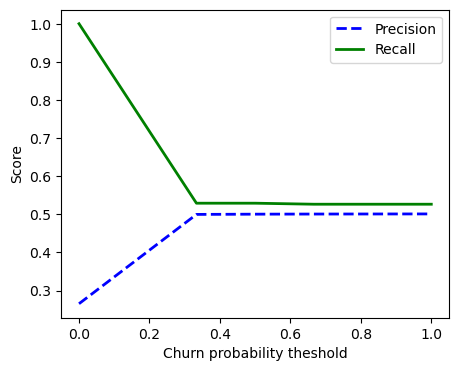

In [30]:
# Plot precision and recall by decision threshold
# Add precision curve
plt.figure(figsize=(5, 4))
plt.plot(
    thresholds,
    precision[:-1],
    'b--',
    label='Precision',
    linewidth=2,
)
# Add recall curve
plt.plot(
    thresholds,
    recall[:-1],
    'g-',
    label='Recall',
    linewidth=2,
    #figsize
)
plt.xlabel('Churn probability theshold')
plt.ylabel('Score')
plt.legend()
plt.show()

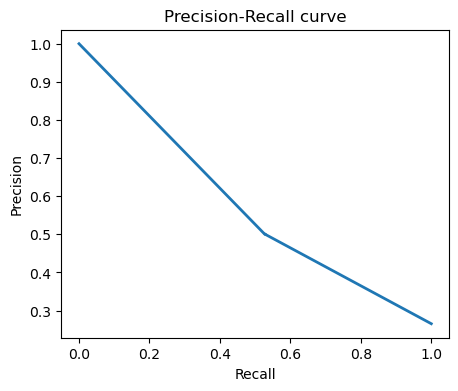

In [31]:
plt.figure(figsize=(5, 4))
plt.plot(
    recall,
    precision,
    linewidth=2,
)
plt.title('Precision-Recall curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.show()